# Formative 2 - Human Activity Recognition with a Hidden Markov Model

**Idea:** the phone sensors show us the movement (observations), but the real activity
(standing, walking, jumping, still) is hidden. The HMM guesses the hidden activity from the sensor data.

**Steps:** 1) load data -> 2) cut into windows -> 3) features -> 4) train/test split -> 5) HMM -> 6) test on unseen data.

## 1. Imports and settings

In [1]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)   # same random numbers every run

In [2]:
DATA_DIR = Path("../data")         # folder with one sub-folder per activity
RESULTS_DIR = Path("../results")   # figures and tables go here
RESULTS_DIR.mkdir(exist_ok=True)

FS = 50        # every phone is converted to 50 samples per second
WINDOW = 100   # window = 100 samples = 2 seconds
STEP = 50      # next window starts 50 samples (1 second) later

# every folder inside data/ is one activity
activities = sorted([f.name for f in DATA_DIR.iterdir() if f.is_dir() and not f.name.startswith(".")])
print(activities)

['Jumping', 'flat_surface', 'standing', 'walking']


**Window size:** a window is a short piece of the recording. One instant tells us nothing,
but 2 seconds shows a full pattern (several steps or jumps). At 50 Hz, 2 seconds = 100 samples.
Windows overlap by 50%, so short recordings give more windows.

## 2. Load the recordings

In [68]:
def load_recording(zip_path):
    z = zipfile.ZipFile(zip_path)                                   # open the zip from Sensor Logger
    files = [n for n in z.namelist() if "__MACOSX" not in n]
    acc_file = [n for n in files if n.lower().endswith("accelerometer.csv")][0]
    gyr_file = [n for n in files if n.lower().endswith("gyroscope.csv")][0]
    acc = pd.read_csv(z.open(acc_file))                             # accelerometer table
    gyr = pd.read_csv(z.open(gyr_file))                             # gyroscope table

    t_acc = acc["seconds_elapsed"].values                           # time of each accelerometer sample
    t_gyr = gyr["seconds_elapsed"].values
    rate_acc = 1 / np.median(np.diff(t_acc))                        # original sampling rate (Hz)
    rate_gyr = 1 / np.median(np.diff(t_gyr))

    # one common time line at 50 Hz (cut 0.25 s at each end where the hand touches the phone)
    t_new = np.arange(max(t_acc[0], t_gyr[0]) + 0.25, min(t_acc[-1], t_gyr[-1]) - 0.25, 1 / FS)

    # resample all 6 columns onto the common time line
    ax = np.interp(t_new, t_acc, acc["x"].values)
    ay = np.interp(t_new, t_acc, acc["y"].values)
    az = np.interp(t_new, t_acc, acc["z"].values)
    gx = np.interp(t_new, t_gyr, gyr["x"].values)
    gy = np.interp(t_new, t_gyr, gyr["y"].values)
    gz = np.interp(t_new, t_gyr, gyr["z"].values)
    signal = np.column_stack([ax, ay, az, gx, gy, gz])

    # some phones give acceleration in m/s2, others in g -> convert to g
    if np.median(np.sqrt(ax ** 2 + ay ** 2 + az ** 2)) > 5:
        signal[:, 0:3] = signal[:, 0:3] / 9.81
    return signal, rate_acc, rate_gyr

def load_csv(csv_path):
    table = pd.read_csv(csv_path)                                  # read one csv file
    signal = table[["ax", "ay", "az", "gx", "gy", "gz"]].values    # the 6 sensor columns
    return signal

In [73]:
CSV_DIR = Path("../data_csv")
rate_rows = []

for activity in activities:
    folder = CSV_DIR / activity
    folder.mkdir(parents=True, exist_ok=True)

    # Process each ZIP recording
    for number, zip_path in enumerate(
        sorted((DATA_DIR / activity).glob("*.zip")), start=1
    ):
        signal, rate_acc, rate_gyr = load_recording(zip_path)

        table = pd.DataFrame(
            signal,
            columns=["ax", "ay", "az", "gx", "gy", "gz"]
        )

        # Add time in seconds
        table.insert(0, "time_s", np.arange(len(signal)) / FS)

        file_name = f"{activity}_{number:02d}.csv"
        table.to_csv(folder / file_name, index=False)

        rate_rows.append({
            "activity": activity,
            "file": file_name,
            "acc_rate_hz": rate_acc,
            "gyr_rate_hz": rate_gyr
        })

    print(activity, ":", number, "CSV files saved")

# Save the original sampling rates
pd.DataFrame(rate_rows).to_csv(
    CSV_DIR / "sampling_rates.csv",
    index=False
)

Jumping : 50 CSV files saved
flat_surface : 50 CSV files saved
standing : 50 CSV files saved
walking : 50 CSV files saved


In [74]:
CSV_DIR = Path("../data_csv")

# Get the activity folder names
activities = sorted([
    f.name for f in CSV_DIR.iterdir()
    if f.is_dir() and not f.name.startswith(".")
])

print(activities)

signals, labels, names = [], [], []

# Load all CSV recordings
for label, activity in enumerate(activities):
    for csv_path in sorted((CSV_DIR / activity).glob("*.csv")):
        signals.append(load_csv(csv_path))
        labels.append(label)
        names.append(csv_path.name)

print("Recordings loaded:", len(signals))

['Jumping', 'flat_surface', 'standing', 'walking']
Recordings loaded: 200


In [75]:
# Load the original sampling rates
rates = pd.read_csv(CSV_DIR / "sampling_rates.csv")

print(
    "\nMy phone's ORIGINAL sampling rate: accelerometer =",
    round(rates["acc_rate_hz"].median(), 1),
    "Hz, gyroscope =",
    round(rates["gyr_rate_hz"].median(), 1),
    "Hz"
)

print("The CSV files are already resampled to", FS, "Hz")


My phone's ORIGINAL sampling rate: accelerometer = 100.3 Hz, gyroscope = 100.3 Hz
The CSV files are already resampled to 50 Hz


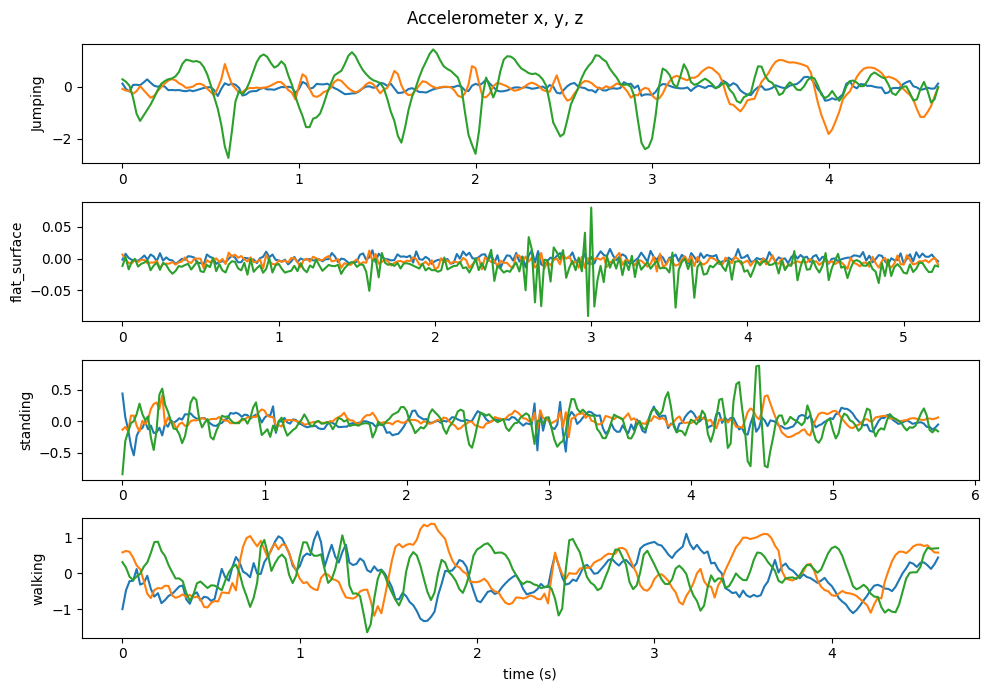

In [76]:
# Plot the accelerometer of one recording per activity
plt.figure(figsize=(10, 7))
for k, activity in enumerate(activities):
    first = labels.index(k)                           # first recording of this activity
    plt.subplot(len(activities), 1, k + 1)
    plt.plot(np.arange(len(signals[first])) / FS, signals[first][:, 0:3])
    plt.ylabel(activity)
plt.xlabel("time (s)")
plt.suptitle("Accelerometer x, y, z")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "raw_samples.png", dpi=150)
plt.show()

## 3. Features (time + frequency)

For each window we calculate 6 numbers:

| Feature | Type | Why |
|---|---|---|
| `acc_mean` | time | average strength of the acceleration |
| `acc_std` | time | how much the acceleration changes (almost 0 when still) |
| `acc_sma` | time | signal magnitude area = total amount of movement |
| `gyr_std` | time | how much the phone rotates |
| `dom_freq` | frequency (FFT) | rhythm of the movement (walking ~2 Hz) |
| `energy` | frequency (FFT) | strength of the rhythm |

`acc_std`, `gyr_std` and `energy` are very small or very big depending on the activity, so we use `log10` to make them easier to compare.

In [43]:
# Names of the features we will calculate
feature_names = [
    "acc_mean",
    "acc_std",
    "acc_sma",
    "gyr_std",
    "dom_freq",
    "energy"
]


def get_features(window):

    # Get accelerometer data (X, Y, Z)
    acc = window[:, 0:3]

    # Get gyroscope data (X, Y, Z)
    gyr = window[:, 3:6]

    # Calculate the total acceleration
    acc_mag = np.sqrt((acc ** 2).sum(axis=1))

    # Calculate the total gyroscope movement
    gyr_mag = np.sqrt((gyr ** 2).sum(axis=1))


    # --------------------------------
    # 1. TIME-DOMAIN FEATURES
    # --------------------------------

    # Average acceleration
    acc_mean = acc_mag.mean()

    # Variation in acceleration
    acc_std = np.log10(acc_mag.std() + 1e-6)

    # Average movement across the three acceleration axes
    acc_sma = np.abs(acc).sum(axis=1).mean()

    # Variation in gyroscope movement
    gyr_std = np.log10(gyr_mag.std() + 1e-6)


    # --------------------------------
    # 2. FREQUENCY-DOMAIN FEATURES
    # --------------------------------

    # Remove the average acceleration
    signal = acc_mag - acc_mag.mean()

    # Convert the signal into frequency information using FFT
    spectrum = np.abs(np.fft.rfft(signal, n=256))

    # Calculate the frequency of each FFT component
    freqs = np.fft.rfftfreq(256, d=1 / FS)

    # Find the frequency with the strongest signal
    dom_freq = freqs[np.argmax(spectrum)]

    # Calculate the total frequency energy
    energy = np.log10(
        np.sum(spectrum ** 2) / 256 + 1e-6
    )


    # Return all six features
    return [
        acc_mean,
        acc_std,
        acc_sma,
        gyr_std,
        dom_freq,
        energy
    ]

In [44]:
def make_windows(signal):
    rows = []

    # Slide through the recording
    for start in range(0, len(signal) - WINDOW + 1, STEP):

        # Extract features from the current window and save them in array
        rows.append(get_features(signal[start:start + WINDOW]))

    return np.array(rows)


# Extract features from all recordings
features = [make_windows(s) for s in signals]

# Display the shape of the first recording
print("Example recording:", features[0].shape, "(windows, features)")

Example recording: (3, 6) (windows, features)


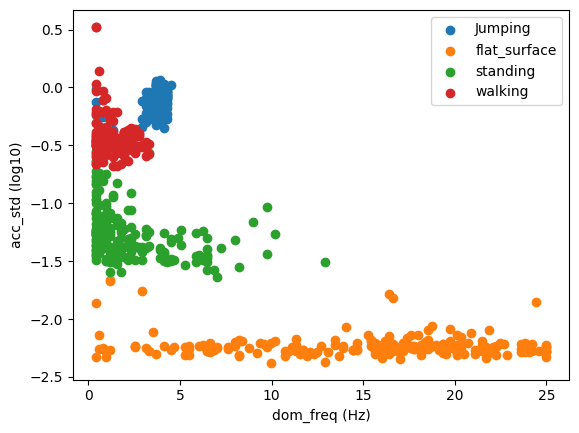

In [45]:
# Combine features from all recordings
all_X = np.vstack(features)

# Create a label for every window
all_y = np.concatenate([
    [labels[i]] * len(features[i])
    for i in range(len(features))
])

# Plot two features for each activity
for k, activity in enumerate(activities):
    plt.scatter(
        all_X[all_y == k, 4],
        all_X[all_y == k, 1],
        label=activity
    )

# Add labels to the graph
plt.xlabel("dom_freq (Hz)")
plt.ylabel("acc_std (log10)")
plt.legend()

# Save and display the graph
plt.savefig(RESULTS_DIR / "feature_scatter.png", dpi=150)
plt.show()

## 4. Train / test split and normalization

The **last 2 recordings of each activity** are kept as **unseen test data**. The model never sees them during training.

In [46]:
train_idx, test_idx = [], []

for k in range(len(activities)):

    # Finds recordings for each activity
    idx = [i for i in range(len(labels)) if labels[i] == k]

    train_idx += idx[:-2]  # Training recordings
    test_idx += idx[-2:]   # Testing recordings

# Display the results
print("Train recordings:", len(train_idx), "| Test recordings:", len(test_idx))
print("Test files:", [names[i] for i in test_idx])

Train recordings: 192 | Test recordings: 8
Test files: ['2026-10-27_16-57-21.zip', '2026-10-27_16-57-27.zip', '2026-10-27_10-12-02.zip', '2026-10-27_10-12-08.zip', '2026-10-27_09-29-10.zip', '2026-10-27_09-29-16.zip', '2026-10-27_09-44-59.zip', '2026-10-27_09-45-06.zip']


**Sequences:** one recording has only one activity, so it never shows a *change* of activity.
We glue recordings together in random order to make one long sequence (for instance  walking -> still -> jumping),
so the HMM can learn transitions. The training recordings are used 5 times in different orders.

In [47]:
def build_sequence(indices):
    # Combine features and labels from selected recordings
    X = np.vstack([features[i] for i in indices])
    y = np.concatenate([[labels[i]] * len(features[i]) for i in indices])

    return X, y


# Shuffle training and testing recordings
train_order = np.concatenate([np.random.permutation(train_idx) for _ in range(5)])
test_order = np.random.permutation(test_idx)

# Build training and testing sequences
X_train, y_train = build_sequence(train_order)
X_test, y_test = build_sequence(test_order)

print("Train windows:", len(X_train), "| Test windows:", len(X_test))

Train windows: 3860 | Test windows: 30


In [28]:
# Z-score normalization: (value - mean) / std, using the TRAINING data only.
# This puts all features on the same scale (they have different units).
mean = X_train.mean(axis=0)
std = X_train.std(axis=0) + 1e-8

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

## 5. The HMM

| Part | In this project |
|---|---|
| Hidden states | the 4 activities |
| Observations | the 6 features of a window |
| `pi` (start probabilities) | chance of starting in each activity |
| `A` (transitions) | chance of going from one activity to another |
| `mu`, `var` (emissions) | average and spread of each feature in each activity (Gaussian) |

**Which algorithms?**
- **Baum-Welch** = training. It improves `pi`, `A`, `mu`, `var` until the log-likelihood stops improving.
- **Viterbi** = prediction. It finds the most likely activity for every window. We use these predictions for accuracy, sensitivity, specificity and the confusion matrix.

In [48]:
def emission(X, mu, var):
    # log-probability of every window under every activity (Gaussian)
    diff = X[:, None, :] - mu[None, :, :]
    return -0.5 * (np.log(2 * np.pi * var)[None, :, :] + diff ** 2 / var[None, :, :]).sum(axis=2)

def forward(pi, A, B):
    T = len(B)
    alpha = np.zeros_like(B)
    scale = np.zeros(T)                         # normalizing numbers (stops values becoming 0)
    alpha[0] = pi * B[0]
    scale[0] = alpha[0].sum()
    alpha[0] = alpha[0] / scale[0]
     # Calculate probabilities from start to end
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ A) * B[t]    # came from any state, now emit B[t]
        scale[t] = alpha[t].sum()
        alpha[t] = alpha[t] / scale[t]
    return alpha, scale

def backward(A, B, scale):
    T = len(B)
    beta = np.ones_like(B)
    for t in range(T - 2, -1, -1):              # go from the end back to the start
        beta[t] = A @ (B[t + 1] * beta[t + 1]) / scale[t + 1]
    return beta

In [49]:
def baum_welch(X, pi, A, mu, var, max_iter=100, tol=1e-5):
    history = []                                                  # log-likelihood of every iteration
    for it in range(max_iter):
        # E-step: how likely is each state at each time?
        log_b = emission(X, mu, var)
        shift = log_b.max(axis=1, keepdims=True)
        B = np.exp(log_b - shift)                                 # shift avoids numbers that are too small
        alpha, scale = forward(pi, A, B)
        beta = backward(A, B, scale)
        loglik = np.log(scale).sum() + shift.sum()
        history.append(loglik)

        gamma = alpha * beta                                      # P(state at time t)
        gamma = gamma / gamma.sum(axis=1, keepdims=True)
        xi_sum = A * (alpha[:-1].T @ (B[1:] * beta[1:] / scale[1:, None]))   # expected transitions

        # M-step: new parameters
        pi = gamma[0] + 1e-3
        pi = pi / pi.sum()
        A = xi_sum + 1e-3
        A = A / A.sum(axis=1, keepdims=True)
        weight = gamma.sum(axis=0)[:, None]
        mu = gamma.T @ X / weight
        var = gamma.T @ (X ** 2) / weight - mu ** 2 + 0.01        # +0.01 keeps the variance above 0

        # convergence check: stop when the log-likelihood barely changes
        if it > 0 and abs(loglik - history[-2]) < tol * abs(history[-2]):
            print("converged after", it + 1, "iterations")
            break
    return pi, A, mu, var, history

In [50]:
def viterbi(X, pi, A, mu, var):
    T = len(X)
    n = len(pi)
    log_b = emission(X, mu, var)
    log_A = np.log(A)
    delta = np.zeros((T, n))                 # best score of a path ending in each state
    back = np.zeros((T, n), dtype=int)       # which state we came from
    delta[0] = np.log(pi) + log_b[0]
    for t in range(1, T):
        scores = delta[t - 1][:, None] + log_A
        back[t] = scores.argmax(axis=0)
        delta[t] = scores.max(axis=0) + log_b[t]
    path = np.zeros(T, dtype=int)
    path[-1] = delta[-1].argmax()            # best last state
    for t in range(T - 2, -1, -1):           # walk back to find the best path
        path[t] = back[t + 1, path[t + 1]]
    return path

## 6. Train the HMM

converged after 13 iterations


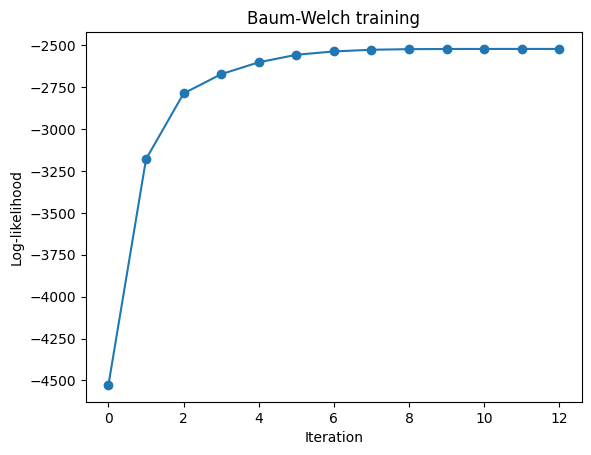

In [51]:
n = len(activities)

# Calculate initial Gaussian parameters
mu = np.array([X_train[y_train == k].mean(axis=0) for k in range(n)])
var = np.array([X_train[y_train == k].var(axis=0) + 0.01 for k in range(n)])

pi = np.ones(n) / n

# Initialize transition probabilities
A = np.ones(shape=(n, n))

for a, b in zip(y_train[:-1], y_train[1:]):
    A[a, b] += 1

A = A / A.sum(axis=1, keepdims=True)

# Train the HMM using Baum-Welch
pi, A, mu, var, history = baum_welch(X_train, pi, A, mu, var)

# Plot training progress
plt.plot(history, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Baum-Welch training")
plt.savefig(RESULTS_DIR / "convergence.png", dpi=150)
plt.show()

## 7. Transition and emission heatmaps

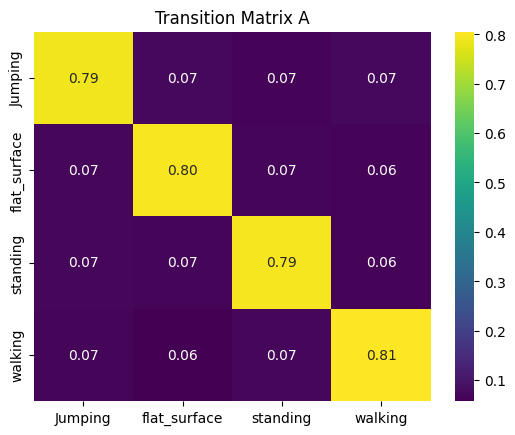

In [52]:
# Plot the transition matrix
sns.heatmap(
    A,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=activities,
    yticklabels=activities
)

plt.title("Transition Matrix A")
plt.savefig(RESULTS_DIR / "transition_matrix.png", dpi=150)
plt.show()

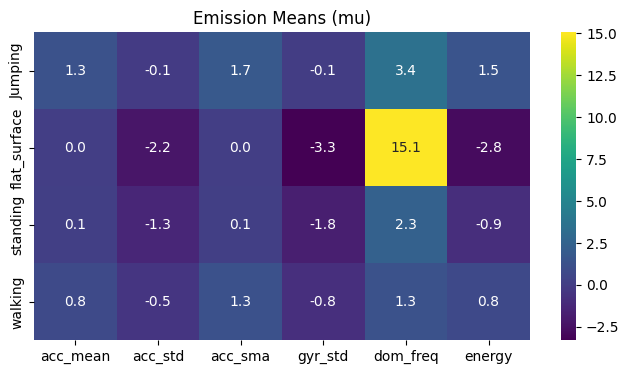

In [53]:
# Plot the average feature values for each activity
plt.figure(figsize=(8, 4))

sns.heatmap(
    mu,
    annot=True,
    fmt=".1f",
    cmap="viridis",
    xticklabels=feature_names,
    yticklabels=activities
)

plt.title("Emission Means (mu)")
plt.savefig(RESULTS_DIR / "emission_means.png", dpi=150)
plt.show()

## 8. Test on unseen data

In [54]:
# Predict activities using Viterbi
pred_train = viterbi(X_train, pi, A, mu, var)
pred_test = viterbi(X_test, pi, A, mu, var)

# Calculate accuracy
print("Train accuracy:", round((pred_train == y_train).mean(), 3))
print("Test accuracy (unseen):", round((pred_test == y_test).mean(), 3))

Train accuracy: 0.963
Test accuracy (unseen): 1.0


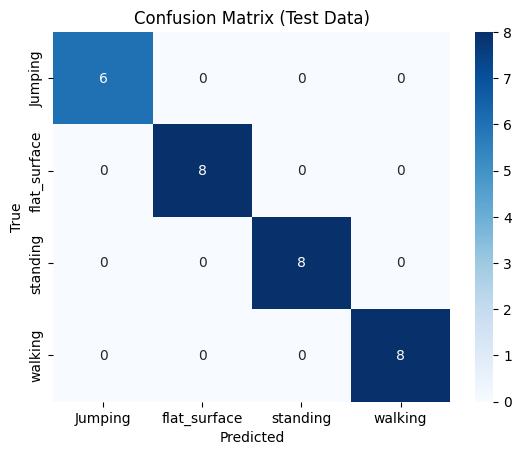

In [55]:
# Create the confusion matrix
cm = np.zeros((n, n), dtype=int)
np.add.at(cm, (y_test, pred_test), 1)

# Plot the confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activities,
    yticklabels=activities
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Data)")

# Save and display the plot
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [56]:
# Calculate TP, FN, FP and TN
TP = np.diag(cm)
FN = cm.sum(axis=1) - TP
FP = cm.sum(axis=0) - TP
TN = cm.sum() - TP - FN - FP

# Calculate evaluation metrics
results = pd.DataFrame({
    "State (Activity)": activities,
    "Number of Samples": cm.sum(axis=1),
    "Sensitivity": TP / (TP + FN),
    "Specificity": TN / (TN + FP),
    "Overall Accuracy": np.trace(cm) / cm.sum()
}).round(3)

# Save the results
results.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)

results

,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,Jumping,6,1.0,1.0,1.0
1,flat_surface,8,1.0,1.0,1.0
2,standing,8,1.0,1.0,1.0
3,walking,8,1.0,1.0,1.0


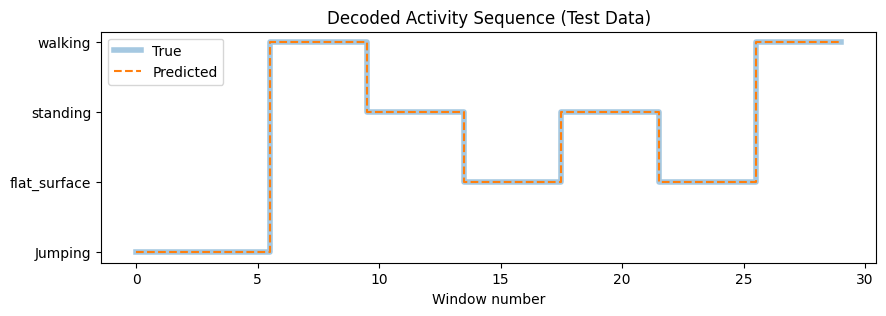

In [57]:
# Plot true and predicted activities over time
plt.figure(figsize=(10, 3))

plt.step(range(len(y_test)), y_test, where="mid",
         linewidth=4, alpha=0.4, label="True")

plt.step(range(len(pred_test)), pred_test, where="mid",
         linestyle="--", label="Predicted")

plt.yticks(range(n), activities)
plt.xlabel("Window number")
plt.legend()
plt.title("Decoded Activity Sequence (Test Data)")

# Save and display the plot
plt.savefig(RESULTS_DIR / "decoded_sequence.png", dpi=150)
plt.show()